# Heaps: VAR estacionário pela parametrização simétrica

## Resumo

Implementamos a transformação de Heaps (2023) para gerar mecanismos Gaussianos VAR(p). Matrizes livres são convertidas em autocorrelações parciais; recursões simétricas recuperam coeficientes e autocovariâncias. O histórico é sorteado da distribuição estacionária conjunta. As equações finais são armazenadas e executadas como ASTs. Avaliamos certificados, duas séries, inicialização, estabilidade operacional e velocidade.

[Paper, Apêndice pp. 11–12](https://arxiv.org/pdf/2004.09455#page=11), [suplemento S1.3, pp. 7–8](https://arxiv.org/src/2004.09455v3/anc/supplMat.pdf), [código oficial consultado](https://arxiv.org/src/2004.09455v3/anc/statprior.stan). A implementação é escrita a partir das equações; a distribuição de amostragem é uma escolha do projeto.

## 1. Critério e pseudocódigo

Transformamos \(U_\ell\) em \(P_\ell=(I+U_\ell U_\ell^\top)^{-1/2}U_\ell\). A implementação usa a identidade SVD que mapeia valores singulares \(u\) em \(u/\sqrt{1+u^2}\). A reconstrução preserva as raízes quadradas simétricas.

A matriz companheira \(B\) organiza os lags do mais recente ao mais antigo. Verificamos \(\rho(B)<1\), a positividade da covariância \(V\) e o resíduo de \(V=BVB^\top+Q\). Os coeficientes finais definem as dependências variável–lag; zeros intermediários podem mudar durante a transformação.

Código: PROJECT_ROOT/src/tsfmxai/generators/heaps.py. Vermelho indica mudanças frente à AST original.
<pre>
1. Derivar semente local por mecanismo.
<span style="color:#c62828">2. Sortear ordem e matrizes U_l; fixar Sigma = sigma^2 I.</span>
<span style="color:#c62828">3. Converter U_l em P_l com valores singulares menores que 1.</span>
<span style="color:#c62828">4. Reconstruir coeficientes e autocovariâncias pelas recursões simétricas.</span>
<span style="color:#c62828">5. Certificar matriz companheira/covariância e armazenar ASTs lineares.</span>
<span style="color:#c62828">6. Sortear o histórico da normal estacionária conjunta.</span>
7. Executar as ASTs com inovação gaussiana.
</pre>

In [1]:
from __future__ import annotations
from dataclasses import asdict, replace
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import subprocess
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits, threadpool_info

PROJECT_ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                    if (p / "src" / "tsfmxai").exists())
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
from tsfmxai.generators import (
    RandomTreeConfig, ContractionTreeConfig, ShaoWuConfig, HeapsVARConfig,
    sample_random_mechanisms, sample_contractive_mechanisms,
    sample_shao_wu_mechanism, sample_shao_wu_mechanisms, sample_shao_wu_trajectories,
    sample_heaps_var_mechanism, sample_heaps_var_mechanisms, sample_heaps_var_trajectories,
    evaluate_expression_with_gradient, evaluate_bound_expression, var_companion_matrix,
    global_expression_bounds,
)
from tsfmxai.evaluation import StabilityDiagnosticConfig, wilson_interval
from tsfmxai.evaluation.generator_tradeoff import benchmark_stability_method
BLAS_CONTROLLER = threadpool_limits(limits=1)
ROOT_SEED = 20261001
HORIZONS = (96, 192, 384)
INNOVATION_STD = .05
DIAGNOSTIC_CONFIG = StabilityDiagnosticConfig(HORIZONS, 100., 3 * INNOVATION_STD, 24)
BASE_CONFIG = RandomTreeConfig(
    minimum_operators=1, maximum_operators=6, num_series=1,
    minimum_lag=1, maximum_lag=12, parameter_probability=.55,
    time_probability=0., lag_probability=.45, add_probability=.80,
    minimum_parameter_magnitude=.05, maximum_parameter_magnitude=.80,
    require_lag=True, require_time=False, coefficient_gate_lags=False,
)
SHAO_CONFIG = ShaoWuConfig(tree_config=BASE_CONFIG, innovation_std=INNOVATION_STD,
                           target_gain=.8)
HEAPS_CONFIG = HeapsVARConfig(num_series=1, minimum_order=1, maximum_order=12,
                             unconstrained_std=.45, innovation_std=INNOVATION_STD)

EXPERIMENT_ID = "heaps_stationary_var"
NOTEBOOK_PATH = "experiments/abstract_syntax_tree/heaps_stationary_var/00_symmetric_var_generation.ipynb"
RESEARCH_QUESTION = "Como gerar VARs multivariados estacionários com coeficientes e histórico conhecidos?"
HYPOTHESIS = "A transformação simétrica satisfaz o certificado e reproduz os momentos estacionários."
COUNT = 256
CASE_CONFIG = replace(HEAPS_CONFIG, num_series=2, minimum_order=1, maximum_order=4)
configuration = {"root_seed": ROOT_SEED, "count": COUNT, "method": asdict(CASE_CONFIG),
                 "diagnostics": asdict(DIAGNOSTIC_CONFIG), "blas_threads": 1,
                 "validation_seed": 272, "trajectory_plot_seed": 812}
print(json.dumps(configuration, indent=2))


{
  "root_seed": 20261001,
  "count": 256,
  "method": {
    "num_series": 2,
    "minimum_order": 1,
    "maximum_order": 4,
    "unconstrained_std": 0.45,
    "innovation_std": 0.05,
    "mean_minimum": 0.0,
    "mean_maximum": 0.0
  },
  "diagnostics": {
    "horizons": [
      96,
      192,
      384
    ],
    "explosion_limit": 100.0,
    "near_zero_radius": 0.15000000000000002,
    "near_zero_tail_steps": 24
  },
  "blas_threads": 1,
  "validation_seed": 272,
  "trajectory_plot_seed": 812
}


**O que foi feito.** Fixamos 256 mecanismos de duas séries. O notebook 6 contém a comparação comum com 5.000 mecanismos univariados.

In [2]:
started = time.perf_counter()
mechanisms = sample_heaps_var_mechanisms(CASE_CONFIG, root_seed=ROOT_SEED, count=COUNT)
sampling_seconds = time.perf_counter() - started
assert all(m.certificate.holds for m in mechanisms)
DEMO = mechanisms[0]
for formula in DEMO.formulas:
    print(formula)
print(DEMO.trees[0])
display(pd.DataFrame([asdict(m.certificate) for m in mechanisms]).describe())


x_0(t) = ((((0 + (0.0512091 * x_0(t-1))) + (0.401819 * x_1(t-1))) + (0.521619 * x_0(t-2))) + (0.350336 * x_1(t-2))) + epsilon_0(t)
x_1(t) = ((((0 + (-0.358642 * x_0(t-1))) + (-0.790705 * x_1(t-1))) + (-0.472136 * x_0(t-2))) + (-0.356404 * x_1(t-2))) + epsilon_1(t)
ADD
    ├── ADD
    │   ├── ADD
    │   │   ├── ADD
    │   │   │   ├── PARAMETER(offset)
    │   │   │   └── MULTIPLY
    │   │   │       ├── PARAMETER(C_0_1)
    │   │   │       └── LAG(x0, L_0_1)
    │   │   └── MULTIPLY
    │   │       ├── PARAMETER(C_1_1)
    │   │       └── LAG(x1, L_1_1)
    │   └── MULTIPLY
    │       ├── PARAMETER(C_0_2)
    │       └── LAG(x0, L_0_2)
    └── MULTIPLY
        ├── PARAMETER(C_1_2)
        └── LAG(x1, L_1_2)


,spectral_radius,maximum_partial_singular_value,minimum_state_covariance_eigenvalue,relative_lyapunov_residual
count,256.000000,256.000000,256.000000,2.560000e+02
mean,0.745041,0.680241,0.001704,3.393407e-16
std,0.187041,0.109848,0.000753,1.709243e-16
min,0.159867,0.212743,0.000239,7.141418e-17
25%,0.625794,0.607449,0.001096,2.219216e-16
50%,0.803402,0.699686,0.001571,3.022349e-16
75%,0.895929,0.755928,0.002500,4.205287e-16
max,0.988982,0.902663,0.003495,1.355277e-15


**O que foi feito.** Retemos as equações executáveis, seus bindings e os certificados antes de simular.

## 2. Verificações analíticas e Monte Carlo

In [3]:
from scipy.linalg import solve_discrete_lyapunov
B = var_companion_matrix(np.asarray(DEMO.coefficients))
Q = np.zeros_like(B)
Q[:DEMO.num_series, :DEMO.num_series] = DEMO.innovation_covariance
independent_covariance = solve_discrete_lyapunov(B, Q)
np.testing.assert_allclose(DEMO.stationary_state_covariance, independent_covariance,
                           rtol=1e-8, atol=1e-11)
mc_paths = sample_heaps_var_trajectories(DEMO, trajectory_count=2000,
                                        generated_steps=16, root_seed=272)
expected = np.asarray(DEMO.stationary_state_covariance)[:DEMO.num_series, :DEMO.num_series]
moment_rows = []
for label, index in [("início", DEMO.order-1), ("após 16 passos", -1)]:
    observed = np.cov(mc_paths[:, :, index], rowvar=False, bias=True)
    moment_rows.append({"instante": label, "covariance_frobenius_error": float(np.linalg.norm(observed-expected)),
                        "observed_mean": mc_paths[:, :, index].mean(axis=0).tolist()})
display(pd.DataFrame(moment_rows))
additional_checks = {
    "certified_mechanisms": sum(m.certificate.holds for m in mechanisms),
    "maximum_companion_radius": max(m.certificate.spectral_radius for m in mechanisms),
    "independent_covariance_max_error": float(np.max(np.abs(independent_covariance-DEMO.stationary_state_covariance))),
    "moment_monte_carlo_count": 2000, "moments": moment_rows,
}


,instante,covariance_frobenius_error,observed_mean
0,início,0.000169,"[-0.00042083356905593184, 0.0003380177993246052]"
1,após 16 passos,0.000343,"[-0.0022888054820132822, 0.0037224777614849824]"


**O que foi feito.** Comparamos a covariância com um solver independente e os momentos em 2.000 trajetórias. As diferenças Monte Carlo permanecem visíveis.

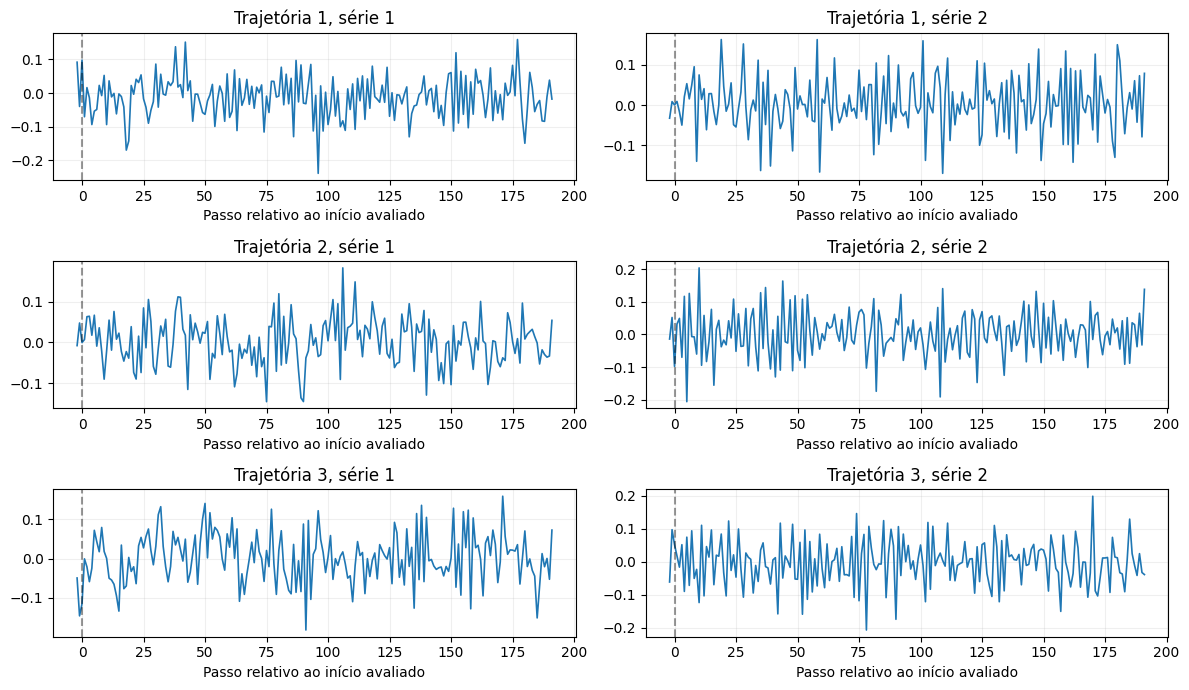

In [4]:
sample_paths = sample_heaps_var_trajectories
paths = sample_paths(DEMO, trajectory_count=3, generated_steps=192, root_seed=812)
fig, axes = plt.subplots(3, DEMO.num_series, figsize=(12, 7), squeeze=False)
for k in range(3):
    for j in range(DEMO.num_series):
        axis = axes[k, j]
        axis.plot(np.arange(-DEMO.order, 192), paths[k, j], lw=1.2)
        axis.axvline(0, color="black", ls="--", alpha=.4)
        axis.set(title=f"Trajetória {k+1}, série {j+1}", xlabel="Passo relativo ao início avaliado")
        axis.grid(alpha=.2)
fig.tight_layout()
plt.show()


**O que foi feito.** As colunas representam variáveis e as linhas, realizações do mesmo mecanismo. O histórico retido aparece à esquerda de zero.

## 3. Estabilidade operacional e velocidade

Explosão: valor não finito ou módulo acima de 100. Cauda de baixa amplitude: todas as variáveis dentro de [-0.15,0.15] nos últimos 24 passos. Os horizontes usam prefixos da mesma trajetória.

In [5]:
results = {"heaps-var": benchmark_stability_method(
    "heaps-var", mechanisms, root_seed=ROOT_SEED, diagnostic_config=DIAGNOSTIC_CONFIG,
    sampling_seconds=sampling_seconds,
)}
outcomes = pd.DataFrame([row for result in results.values() for row in result["outcomes"]])
performance = pd.DataFrame([result["performance"] for result in results.values()])
summary = outcomes.groupby(["method", "horizon"], sort=False).agg(
    N=("sample_index", "size"), explosions=("exploded", "sum"),
    explosion_rate=("exploded", "mean"), near_zero=("near_zero", "sum"),
    near_zero_rate=("near_zero", "mean"), neither=("neither", "sum"),
    nonfinite=("nonfinite", "sum"),
    finite_threshold_crossings=("finite_threshold_crossing", "sum"),
).reset_index()
for count, rate in (("explosions", "explosion"), ("near_zero", "near_zero")):
    intervals = [wilson_interval(int(k), int(n)) for k, n in zip(summary[count], summary["N"])]
    summary[rate + "_wilson_95_low"] = [v[0] for v in intervals]
    summary[rate + "_wilson_95_high"] = [v[1] for v in intervals]
display(summary)
display(performance)


,method,horizon,N,explosions,explosion_rate,near_zero,near_zero_rate,neither,nonfinite,finite_threshold_crossings,explosion_wilson_95_low,explosion_wilson_95_high,near_zero_wilson_95_low,near_zero_wilson_95_high
0,heaps-var,96,256,0,0.0,78,0.304688,178,0,0,0.0,0.014784,0.251536,0.363614
1,heaps-var,192,256,0,0.0,89,0.347656,167,0,0,0.0,0.014784,0.291961,0.407856
2,heaps-var,384,256,0,0.0,84,0.328125,172,0,0,0.0,0.014784,0.273520,0.387812


,method,mechanisms,sampling_and_certificate_seconds,mechanisms_per_second,initialization_seconds,innovation_seconds,ast_execution_seconds,diagnostic_seconds,evaluation_seconds,total_seconds,attempted_trajectories_per_second,successful_full_trajectories_per_second,full_horizon_success_rate,evaluated_steps,evaluated_values,ast_values_per_second,end_to_end_values_per_second
0,heaps-var,256,0.388024,659.753685,0.02169,0.016718,3.561271,0.027007,3.649914,4.037937,63.398703,63.398703,1.0,98304,196608,55207.25296,48690.203849


**O que foi feito.** A avaliação separa amostragem/certificação, inicialização, inovações, execução e diagnóstico. O tempo total inclui todos esses custos.

## Interpretação

O gerador cobre dependências lineares com vários lags e variáveis. A inicialização conjunta é estacionária em aritmética ideal, com tolerâncias numéricas verificadas. A distribuição das matrizes livres determina persistência e diversidade. Interações não lineares pertencem às outras famílias.

## Registro completo do experimento

Configuração, sementes, proveniência, métricas, síntese e reprodução ficam nesta célula.

In [6]:
def git_output(*args):
    try:
        return subprocess.check_output(["git", *args], cwd=PROJECT_ROOT,
                                       text=True, stderr=subprocess.DEVNULL).strip()
    except (subprocess.CalledProcessError, FileNotFoundError):
        return None

source_paths = [
    "src/tsfmxai/representations/expression.py",
    "src/tsfmxai/generators/random_expression.py",
    "src/tsfmxai/generators/trajectory.py",
    "src/tsfmxai/generators/stochastic.py",
    "src/tsfmxai/generators/contraction.py",
    "src/tsfmxai/generators/shao_wu.py",
    "src/tsfmxai/generators/heaps.py",
    "src/tsfmxai/evaluation/stability.py",
    "src/tsfmxai/evaluation/generator_tradeoff.py",
]
record = {
    "experiment_id": EXPERIMENT_ID, "status": "executed",
    "research_question": RESEARCH_QUESTION,
    "hypothesis": HYPOTHESIS,
    "configuration": configuration,
    "seed_policy": {
        "mechanisms": "derive_sample_seed(ROOT_SEED, index)",
        "benchmark_initialization_and_future_noise": "SeedSequence([ROOT_SEED, index, 991]).spawn(2)",
        "multiple_trajectories": "SeedSequence([root_seed, trajectory_index]).spawn(2)",
        "external_global_rng": False,
        "note": "Per-index local streams isolate generation from user RNG state and worker scheduling.",
    },
    "provenance": {
        "git_head": git_output("rev-parse", "HEAD"), "dirty_worktree": bool(git_output("status", "--porcelain")),
        "source_sha256": {name: hashlib.sha256((PROJECT_ROOT / name).read_bytes()).hexdigest()
                          for name in source_paths},
        "python": sys.version, "platform": platform.platform(),
        "packages": {name: importlib.metadata.version(name)
                     for name in ("numpy", "pandas", "matplotlib", "joblib", "threadpoolctl", "scipy")},
        "blas": threadpool_info(), "execution": "serial wall-clock; BLAS threads=1",
        "references": {"Shao-Wu": "https://arxiv.org/abs/math/0611029",
                       "Heaps": "https://arxiv.org/abs/2004.09455"},
    },
    "metrics": {"stability": json.loads(summary.to_json(orient="records")),
                "performance": json.loads(performance.to_json(orient="records")),
                "additional_checks": additional_checks},
    "scientific_summary": [
        f"{r.method}: h={r.horizon}, {r.explosions}/{r.N} threshold failures; "
        f"{r.near_zero}/{r.N} low-amplitude tails."
        for r in summary[summary.horizon.eq(max(HORIZONS))].itertuples()
    ],
    "limitations": [
        "near_zero means all final 24 values within +/-0.15, a finite-window low-amplitude label.",
        "Gaussian stationary samples may cross a finite threshold; threshold crossing and nonfinite outputs are recorded separately.",
        "One independent mechanism/realization per outcome denominator; Wilson intervals are over these samples.",
        "Families and native initialization/noise laws differ; matched variance does not make noise distributions identical.",
        "Shao-Wu initialization is approximate with a certified L2 coupling-error bound; Heaps uses a joint invariant Gaussian history.",
        "Single-run timings include failed attempts; they are hardware-dependent, without timing confidence intervals.",
        "The mathematical mappings are published; random AST construction and explanation-ready storage are project adaptations.",
    ],
    "reproduction_command": (
        ".\\.venv\\Scripts\\python.exe -m jupyter nbconvert --to notebook --execute --inplace "
        + NOTEBOOK_PATH + " --ExecutePreprocessor.timeout=3600"
    ),
}
print(json.dumps(record, indent=2, ensure_ascii=False))


{
  "experiment_id": "heaps_stationary_var",
  "status": "executed",
  "research_question": "Como gerar VARs multivariados estacionários com coeficientes e histórico conhecidos?",
  "hypothesis": "A transformação simétrica satisfaz o certificado e reproduz os momentos estacionários.",
  "configuration": {
    "root_seed": 20261001,
    "count": 256,
    "method": {
      "num_series": 2,
      "minimum_order": 1,
      "maximum_order": 4,
      "unconstrained_std": 0.45,
      "innovation_std": 0.05,
      "mean_minimum": 0.0,
      "mean_maximum": 0.0
    },
    "diagnostics": {
      "horizons": [
        96,
        192,
        384
      ],
      "explosion_limit": 100.0,
      "near_zero_radius": 0.15000000000000002,
      "near_zero_tail_steps": 24
    },
    "blas_threads": 1,
    "validation_seed": 272,
    "trajectory_plot_seed": 812
  },
  "seed_policy": {
    "mechanisms": "derive_sample_seed(ROOT_SEED, index)",
    "benchmark_initialization_and_future_noise": "SeedSequence(

**O que foi feito.** Os resultados e hashes das fontes ficam incorporados ao notebook executado, sem sidecars duplicados.